# Projeto da disciplina de Aprendizado de Máquina
## Criatura Lendária 2 - Tiamat

------

Docente: Daniel Roberto Cassar  
Discente: Maria Clara Costa Ferreira  

## Introdução

A barreira hematoencefálica (BHE) é uma rede capilar altamente seletiva que separa o cérebro do sistema circulatório e impede que substâncias neurotóxicas presentes no sangue atravessem para o fluido extracelular do sistema nervoso central (SNC) [https://www.nature.com/articles/s41597-021-01069-5]. Prever se uma substância atravessa a BHE é muito importante, pois pode ajudar no desenvolvimento de novos fármacos que visam combater doenças do SNC e a identificar compostos em formulações que tem como alvo outras regiões que devem ser evitados, pois podem causar efeitos adversos. [https://www.nature.com/articles/s41598-024-66897-y?fromPaywallRec=false]

O conjunto de dados Blood-Brain Barrier Database (B3DB) reúne milhares de descritores moleculares. Estes, por sua vez, são representações matemáticas usadas para descrever quantitativamente as informações físico-químicas das moléculas. Cada descritor leva em consideração uma pequena parte de toda a informação química contida na molécula real, e seu conjunto pode ser usado principalmente para busca de similaridade [https://www.sciencedirect.com/topics/medicine-and-dentistry/molecular-descriptor]. Além disso, o dataset de classificação também conta com um rótulo que informa se a molécula é permeável ou impermeável à BHE.

O objetivo do presente trabalho é, portanto, utilizar esses descritores para prever se a substância atravessa ou não a barreira hematoencefálica.

## Bibliotecas

Para o desenvolvimento desse código foram utilizadas as seguintes bibliotecas:

In [36]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif
from sklearn.ensemble import ExtraTreesClassifier
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from optuna import create_study
import matplotlib.pyplot as plt
from functools import partial
from rdkit import Chem
import pandas as pd
import seaborn as sns
import optuna
import warnings

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings(
    "ignore",
    message = "Skipping features without any observed values",
    category = UserWarning,
)

****************************

## Análise exploratória dos dados

In [37]:
# load extended classification dataset
df_classificacao = pd.read_csv("classification_extended_test.tsv",
                                           sep="\t")

C:\Users\maria2610071\AppData\Local\Temp\ipykernel_32628\2422661761.py:2: DtypeWarning: Columns (0: comments) have mixed types. Specify dtype option on import or set low_memory=False.
  df_classificacao = pd.read_csv("classification_extended_test.tsv",


In [3]:
df_classificacao

,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,BBB+/BBB-,Inchi,threshold,reference,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,1,sulphasalazine,2-hydroxy-5-[[4-(pyridin-2-ylsulfamoyl)phenyl]...,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,5339.0,-2.69,BBB-,InChI=1S/C18H14N4O5S/c23-16-9-6-13(11-15(16)18...,NaN,R2|R2|R25|R46|,...,10.171643,63.201012,398.068491,9.477821,2428,42,144,165,9.590278,6.097222
1,2,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,3889.0,-2.52,BBB-,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,NaN,R25|,...,10.893010,87.033695,520.101247,9.287522,4114,62,194,237,13.756944,7.916667
2,3,clioquinol,5-chloro-7-iodoquinolin-8-ol,Oc1c(I)cc(Cl)c2cccnc12,2788.0,-2.40,BBB-,InChI=1S/C9H5ClINO/c10-6-4-7(11)9(13)8-5(6)2-1...,NaN,R18|R26|R27|,...,9.618402,44.825548,304.910439,16.939469,218,21,68,81,4.805556,2.861111
3,4,bbcpd11 (cimetidine analog) (y-g13),2-[2-[(3-bromopyridin-2-yl)methylsulfanyl]ethy...,CCNC(=NCCSCc1ncccc1Br)NC#N,14022517.0,-2.15,BBB-,InChI=1S/C12H16BrN5S/c1-2-15-12(18-9-14)17-6-7...,NaN,R2|R2|R8|R40|R2|R2|R2|R2|R18|R21|R25|R25|R26|R...,...,9.201199,50.610337,341.030979,9.743742,898,22,82,88,6.583333,4.694444
4,5,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,18595497.0,-2.15,BBB-,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,NaN,R25|,...,10.992336,85.350582,461.168581,7.686143,2850,74,198,254,11.229167,6.847222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7802,7803,antazoline,"n-benzyl-n-(4,5-dihydro-1h-imidazol-2-ylmethyl...",c1ccc(CN(CC2=NCCN2)c2ccccc2)cc1,2200.0,NaN,BBB-,InChI=1S/C17H19N3/c1-3-7-15(8-4-1)13-20(14-17-...,NaN,R14|R23|R50|,...,9.582249,66.060685,265.157898,6.798920,829,24,100,113,4.444444,4.527778
7803,7804,emedastine,"1-(2-ethoxyethyl)-2-(4-methyl-1,4-diazepan-1-y...",CCOCCn1c(N2CCCN(C)CC2)nc2ccccc21,3219.0,NaN,BBB+,InChI=1S/C17H26N4O/c1-3-22-14-13-21-16-8-5-4-7...,NaN,R15|R23|R50|,...,9.863134,70.340391,302.210661,6.296055,1041,35,112,131,6.166667,5.027778
7804,7805,ketotifen,2-(1-methylpiperidin-4-ylidene)-6-thiatricyclo...,CN1CCC(=C2c3ccccc3CC(=O)c3sccc32)CC1,3827.0,NaN,BBB+,InChI=1S/C19H19NOS/c1-20-9-6-13(7-10-20)18-15-...,NaN,R15|R27|R50|,...,10.124268,70.590222,309.118735,7.539481,917,40,122,148,5.888889,4.750000
7805,7806,milrinone,6-methyl-2-oxo-5-pyridin-4-yl-1h-pyridine-3-ca...,Cc1[nH]c(=O)c(C#N)cc1-c1ccncc1,4197.0,NaN,BBB-,InChI=1S/C12H9N3O/c1-8-11(9-2-4-14-5-3-9)6-10(...,NaN,R15|R23|R27|,...,9.618801,48.335122,211.074562,8.442982,425,24,80,93,5.555556,3.666667


In [4]:
n_moleculas = df_classificacao.shape[0]
n_colunas = df_classificacao.shape[1]
print(f"O número de moléculas nesse dataset é {n_moleculas}.")
print(f"Enquanto isso, existem {n_colunas} colunas nesse dataset.")

O número de moléculas nesse dataset é 7807.
Enquanto isso, existem 1625 colunas nesse dataset.


In [5]:
df_classificacao.columns

Index(['NO.', 'compound_name', 'IUPAC_name', 'SMILES', 'CID', 'logBB',
       'BBB+/BBB-', 'Inchi', 'threshold', 'reference',
       ...
       'SRW10', 'TSRW10', 'MW', 'AMW', 'WPath', 'WPol', 'Zagreb1', 'Zagreb2',
       'mZagreb1', 'mZagreb2'],
      dtype='str', length=1625)

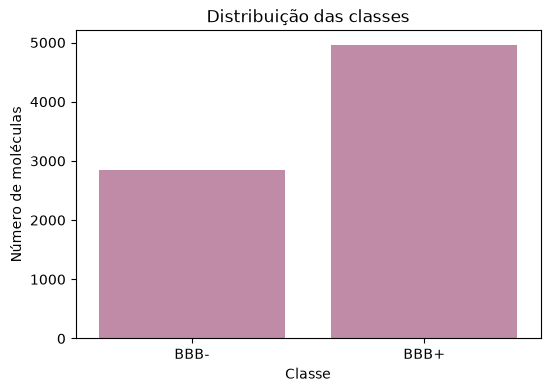

In [102]:
TARGET = "BBB+/BBB-"

plt.figure(figsize = (6 ,4))
sns.countplot(data = df_classificacao, x = TARGET, color = "#C982A8")
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Número de moléculas")
plt.show()

In [7]:
print(f"Existem {df_classificacao.isna().all().sum()} atributos completamente vazios.")

Existem 76 atributos completamente vazios.


In [8]:
identificadores = ["NO.", "compound_name", "IUPAC_name", "CID", "logBB",
        "Inchi", "threshold", "reference", "group", "comments"]

#Criando dataframe para modelagem
df_modelagem = df_classificacao.drop(columns = identificadores).copy()
colunas_vazias = df_modelagem.columns[df_modelagem.isna().all()]
df_modelagem = df_modelagem.drop(columns = colunas_vazias)

#Separa os dados
ATRIBUTOS = df_modelagem.drop(columns = ["BBB+/BBB-", "SMILES"])
TARGET = df_modelagem["BBB+/BBB-"]
SMILES = df_modelagem["SMILES"].copy()

In [9]:
# Define-se a quantidade de ausentes por atributo
ausentes = ATRIBUTOS.isna().sum()
porcentagem_ausentes = ATRIBUTOS.isna().mean() * 100

print(f"""
    Atributos com valores ausentes: {(ausentes > 0).sum()}
    O total de valores ausentes é: {ausentes.sum()}.
    """)


    Atributos com valores ausentes: 804
    O total de valores ausentes é: 604601.
    


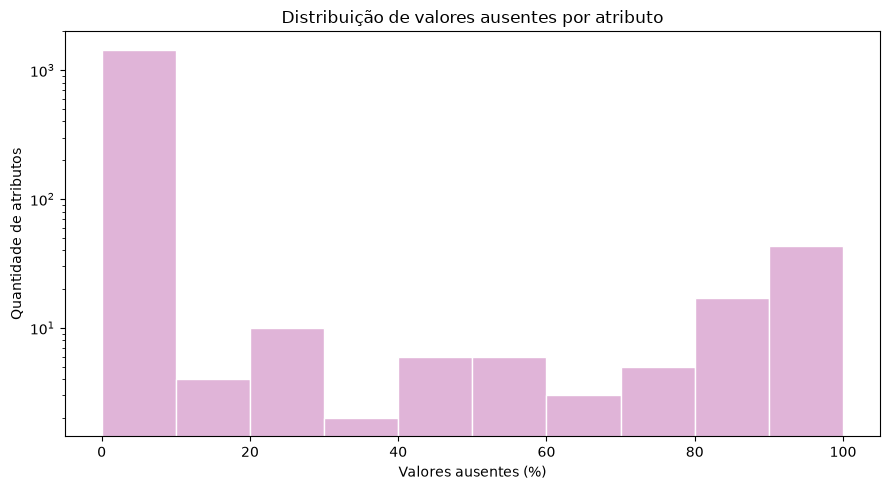

In [10]:
plt.figure(figsize=(9,5))

sns.histplot(
    porcentagem_ausentes,
    bins=10,
    edgecolor="white",
    color = "#D69BCB"
)

plt.xlabel("Valores ausentes (%)")
plt.ylabel("Quantidade de atributos")
plt.yscale("log")
plt.title("Distribuição de valores ausentes por atributo")
plt.tight_layout()
plt.show()

## Separação de treino e teste – (MurckoScaffold)

In [11]:
# Aqui se usa MurckoScaffold

SEMENTE_ALEATORIA = 1912

def scaffold(smiles):
    
    mol = Chem.MolFromSmiles(smiles)
    
    if mol is None:
        return None
        
    sc = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    
# Sem anel -> Scaffold vazio e usa o próprio SMILES
    if sc != "":
        return sc
    else:
        return smiles

# Calcula Scaffolds
df_modelagem["scaffold"] = df_modelagem["SMILES"].apply(scaffold)

# Remove SMILES inválidos
df_modelagem = df_modelagem.dropna(subset=["scaffold"]).copy()
grupos = df_modelagem["scaffold"].astype("category").cat.codes


[23:15:09] Explicit valence for atom # 10 C, 4, is greater than permitted
[23:15:12] Explicit valence for atom # 10 C, 4, is greater than permitted


In [12]:
# Aqui se usa GroupShuffleSplit
# Divisão em treino e teste baseada em scaffolds

gss = GroupShuffleSplit(
    n_splits = 1,
    test_size = 0.1,
    random_state = SEMENTE_ALEATORIA
)

indices_treino, indices_teste = next(
    gss.split(
        df_modelagem[ATRIBUTOS.columns],
        df_modelagem[TARGET.name],
        groups = grupos
    )
)

df_treino = df_modelagem.iloc[indices_treino]
df_teste = df_modelagem.iloc[indices_teste]

X_treino, y_treino = df_treino[ATRIBUTOS.columns], df_treino[TARGET.name]
X_teste, y_teste = df_teste[ATRIBUTOS.columns], df_teste[TARGET.name]

## Modelo Baseline

In [13]:
# Aqui se usa DummyClassifier

modelo_baseline = DummyClassifier()
modelo_baseline.fit(X_treino, y_treino)

DummyClassifier()

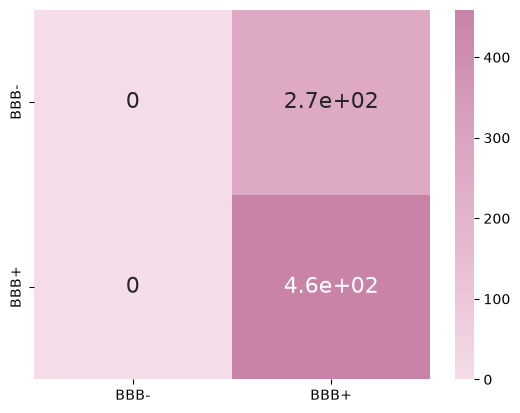

In [88]:
# Aqui se usa confusion_matrix
ordem_labels = df_modelagem["BBB+/BBB-"].unique().tolist()

y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

# Aquis se usa LinearSegmentedColormap

paleta = LinearSegmentedColormap.from_list(
    "soft_scientific",
    [ "#F4DCE8",
    "#E8BBD0",
    "#D9A3C1",
    "#C982A8",]
)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap = paleta);

In [89]:
# Aqui se usa accuracy_score

acuracia = accuracy_score(y_verdadeiro, y_previsao)

print(f"Acurácia = {(acuracia*100):.2f}%")

Acurácia = 63.22%


In [26]:
import numpy as np
X = X_treino.to_numpy(dtype=float)
print("NaNs:", np.isnan(X).sum())

NaNs: 549450


## Seleção de atributos

In [78]:
def cria_instancia_extratree(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    selecao = SelectKBest(score_func= f_classif,
                          k=trial.suggest_int("k", 20, 500))

    modelo = make_pipeline(
        SimpleImputer(strategy="median"),
        VarianceThreshold(),          # tira colunas constantes
        selecao,
        DecisionTreeClassifier(
            max_depth = trial.suggest_int("max_depth", 2, 20),
            random_state = SEMENTE_ALEATORIA
        )
    )
    return modelo

In [79]:
NUM_FOLDS = 10

grupos_treino = df_treino["scaffold"]
cv = StratifiedGroupKFold(n_splits = NUM_FOLDS, shuffle = True, random_state = SEMENTE_ALEATORIA)

In [80]:
# Aqui se usa cross_val_score
def funcao_objetivo(trial, X, y):
    """Função objetivo do optuna

    """

    modelo = cria_instancia_extratree(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="roc_auc",
        cv=cv,
        groups = grupos_treino,
    )

    return metricas.mean()

In [81]:
# Aqui se usa create_study

NOME_DO_ESTUDO = "selecao_arvores_BBB_v4"

objeto_de_estudo = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [82]:
# Aqui se usa a função partial

funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino
)

In [100]:
NUM_TENTATIVAS = 100

objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [101]:
melhor_trial = objeto_de_estudo.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Melhores parâmetros: {objeto_de_estudo.best_params}")
print(f"Melhor ROC-AUC: {objeto_de_estudo.best_value}")

Número do melhor trial: 42
Melhores parâmetros: {'k': 347, 'max_depth': 5}
Melhor ROC-AUC: 0.8274947029571262


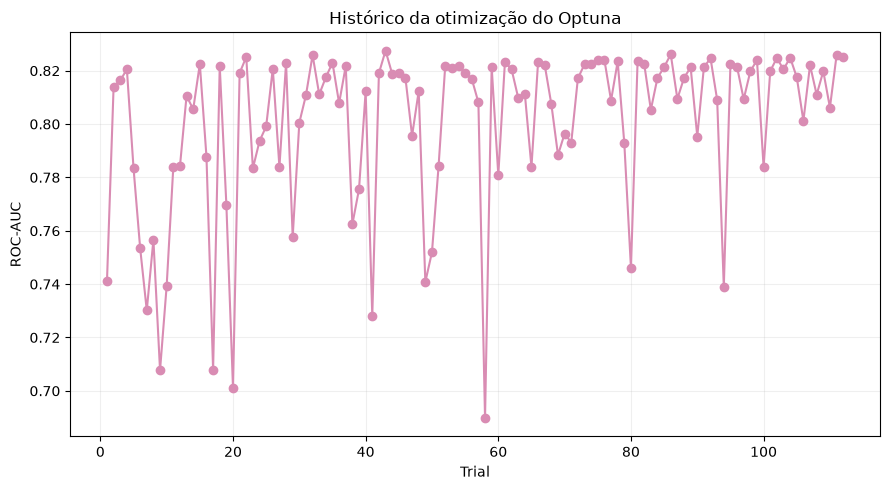

In [103]:
resultados = [trial.value for trial in objeto_de_estudo.trials]

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(resultados) + 1), resultados, "o-", color="#D98CB3")

plt.xlabel("Trial")
plt.ylabel("ROC-AUC")
plt.title("Histórico da otimização do Optuna")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [104]:
melhor_modelo = cria_instancia_extratree(
    optuna.trial.FixedTrial(objeto_de_estudo.best_params)
)

melhor_modelo.fit(X_treino, y_treino)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('variancethreshold', VarianceThreshold()),
                ('selectkbest', SelectKBest(k=347)),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=5, random_state=1912))])

In [105]:
selecao = melhor_modelo.named_steps["selectkbest"]

atributos_disponiveis = X_treino.columns[
    melhor_modelo.named_steps["variancethreshold"].get_support()
]

atributos_selecionados = atributos_disponiveis[selecao.get_support()]

print(f"Quantidade de atributos:{len(atributos_selecionados)}")
print(atributos_selecionados.tolist())

Quantidade de atributos:347
['ABC', 'ABCGG', 'nAcid', 'SpAbs_A', 'SpAD_A', 'LogEE_A', 'VE2_A', 'VR3_A', 'nHeavyAtom', 'nHetero', 'nN', 'nO', 'nS', 'ATS0dv', 'ATS1dv', 'ATS2dv', 'ATS3dv', 'ATS4dv', 'ATS5dv', 'ATS6dv', 'ATS7dv', 'ATS8dv', 'ATS0d', 'ATS8d', 'ATS0s', 'ATS1s', 'ATS2s', 'ATS3s', 'ATS4s', 'ATS5s', 'ATS7s', 'ATS8s', 'ATS0Z', 'ATS1Z', 'ATS2Z', 'ATS4Z', 'ATS5Z', 'ATS6Z', 'ATS7Z', 'ATS8Z', 'ATS1m', 'ATS2m', 'ATS4m', 'ATS5m', 'ATS6m', 'ATS7m', 'ATS8m', 'ATS0v', 'ATS7v', 'ATS8v', 'ATS0se', 'ATS1se', 'ATS8se', 'ATS0pe', 'ATS1pe', 'ATS8pe', 'ATS0are', 'ATS1are', 'ATS8are', 'ATS0p', 'ATS8p', 'ATS1i', 'AATS4dv', 'AATS5dv', 'AATS6dv', 'AATS7dv', 'AATS8dv', 'AATS6d', 'AATS7d', 'AATS8d', 'AATS6s', 'AATS7s', 'AATS8s', 'AATS5Z', 'AATS6Z', 'AATS7Z', 'AATS5m', 'AATS6m', 'AATS7v', 'AATS8v', 'AATS1se', 'AATS4se', 'AATS5se', 'AATS6se', 'AATS7se', 'AATS8se', 'AATS1pe', 'AATS4pe', 'AATS5pe', 'AATS6pe', 'AATS7pe', 'AATS8pe', 'AATS1are', 'AATS4are', 'AATS5are', 'AATS6are', 'AATS7are', 'AATS8are', 'A

## K-Nearest Neighbors

### Modelo e espaço de busca

def cria_instancia_knn(trial):
    """Cria uma instância do modelo.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
     k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)

    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 200, log = True),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan", "minkowski"]),
        # argumentos fixos
        "n_jobs": -1,
    }
    if parametros["metric"] == "minkowski":
            parametros["p"] = trial.suggest_int("p", 1, 2)
         
    modelo = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(**parametros)
    )

    return modelo

## Árvore de Decisão

def cria_instancia_arvore(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)
    
    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("criterion", ["squared_error", "absolute_error"]), #critério de split
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 5, 100),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(), #Tira colunas constantes
        selecao,
        DecisionTreeRegressor(**parametros)
    )

    return modelo

## Floresta Aleatória

def cria_instancia_floresta(trial):
    """Cria uma instância do modelo de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
     k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000, log=True),
        "criterion": trial.suggest_categorical("criterion", ["squared_error", "absolute_error"]), #critério de split
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

     modelo = make_pipeline(
        selecao,
        StandardScaler(),
        DecisionTreeRegressor(**parametros)
    )

    return modelo

## Apêndice I - Nota sobre a abordagem de classificação

A proposta inicial desse trabalho era desenvolver modelos de regressão para prever os valores quantitativos de permeabilidade na barreira hematoencefálica (logBB), utilizando o dataset "B3DB_regression_extended.tsv.gz", do banco Blood-Brain Barrier Dataset (B3DB).

No entanto, apesar do pipeline ter seguido boas práticas rigorosas, dividindo os dados por famílias químicas e fazendo otimização de hiperparâmetros com o Optuna, já no primeiro modelo o RMSE foi de 0,7 unidades de logBB. Isso significa que o modelo errava na razão entre as concentrações cerebrais e sanguíneas por um fator de 5 vezes (já que $10^{0,7}\approx 5\$)

A razão para isso acontecer, que também se repetiria nos outros modelos, é que:  
-o volume de dados era bastante limitado, com pouco mais de 1000 compostos, o que dificulta o aprendizado de relações mais complexas  
-nesse trabalho foi utilizada a divisão por scaffolds, forçando o modelo a prever o logBB de famílias químicas inéditas. Com testes rigorosos e mais realistas assim, o RMSE tende a ser mais alto.

https://medium.com/data-hackers/como-selecionar-as-melhores-features-para-seu-modelo-de-machine-learning-faf74e357913